# 04 User-based KNN

**Idea:** to guess how a user would rate a movie, find the users whose taste is most similar (the *neighbours*) and look at how they rated it. The model is in `src/knn.py`; this notebook answers three questions:

1. Which settings work best: how many neighbours (`n_neighbors`) and how much damping (`damping`)?
2. Does KNN beat the baselines from notebook 02?
3. Where does it still struggle?

Rating quality is measured with RMSE and MAE (lower is better). The quality of the top-10 list is measured with Precision, Recall and NDCG at 10 (higher is better). All of them come from `src/metrics.py`.

In [1]:
import sys
sys.path.insert(0, "..")  # so that `src` can be imported from the notebooks folder

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.baselines import MovieMean
from src.data import load_ratings, user_time_split
from src.knn import UserKNN
from src.metrics import evaluate_ranking, mae, rmse

K = 10  # length of the recommendation list
ratings = load_ratings()

In [2]:
def evaluate(model, train, test, k=K):
    """Fit the model on `train`, score it on `test`, and return one row of results."""
    model.fit(train)
    predictions = model.predict(test)
    recommendations = {user: model.recommend(user, k) for user in test["userId"].unique()}
    ranking = evaluate_ranking(recommendations, test, k)
    return {
        "model": model.name,
        "rmse": rmse(test["rating"], predictions),
        "mae": mae(test["rating"], predictions),
        f"precision@{k}": ranking[f"precision@{k}"],
        f"recall@{k}": ranking[f"recall@{k}"],
        f"ndcg@{k}": ranking[f"ndcg@{k}"],
    }

## 1. Choosing the settings without cheating

If we tried many settings and kept the one that scores best **on the test set**, the test score would be too optimistic: we would have picked the settings that happen to suit those exact ratings. So we cut a **validation set** out of the training data and use *that* to choose. The test set stays untouched until the final check.

```
all ratings
 ├─ train  ── fit_train   (the model learns from this while we compare settings)
 │          └ validation  (newest 20% of each user's train ratings: we choose settings here)
 └─ test                  (used once, at the very end)
```

Both cuts use `user_time_split`: for every user, the newest 20% of their ratings are held out.

In [3]:
train, test = user_time_split(ratings)  # test is locked away until section 2
fit_train, validation = user_time_split(train)
print(f"fit_train: {len(fit_train):,}   validation: {len(validation):,}   test: {len(test):,}")

fit_train: 64,960   validation: 15,936   test: 19,940


We try every combination of:

- `n_neighbors`: how many similar users are consulted (few = specific but noisy, many = stable but vague)
- `damping`: how strongly a movie's score is pulled toward the user's own average when only little neighbour evidence exists (0 = no pulling)

In [4]:
N_NEIGHBORS = [10, 20, 50, 100, 200]
DAMPING = [0, 1, 2, 5, 10]

rows = []
for n in N_NEIGHBORS:
    for d in DAMPING:
        rows.append({"n_neighbors": n, "damping": d} | evaluate(UserKNN(n, d), fit_train, validation))
grid = pd.DataFrame(rows)
grid.drop(columns="model").round(4)

,n_neighbors,damping,rmse,mae,precision@10,recall@10,ndcg@10
0,10,0,0.9745,0.7491,0.0215,0.0309,0.0290
1,10,1,0.9271,0.7152,0.0550,0.0695,0.0795
2,10,2,0.9352,0.7233,0.0569,0.0733,0.0841
3,10,5,0.9437,0.7316,0.0584,0.0752,0.0848
4,10,10,0.9475,0.7352,0.0598,0.0791,0.0867
5,20,0,0.9627,0.7375,0.0097,0.0134,0.0131
6,20,1,0.9181,0.7069,0.0593,0.0725,0.0839
7,20,2,0.9283,0.7170,0.0649,0.0832,0.0928
8,20,5,0.9396,0.7279,0.0673,0.0877,0.0973
9,20,10,0.9451,0.7331,0.0681,0.0897,0.0991


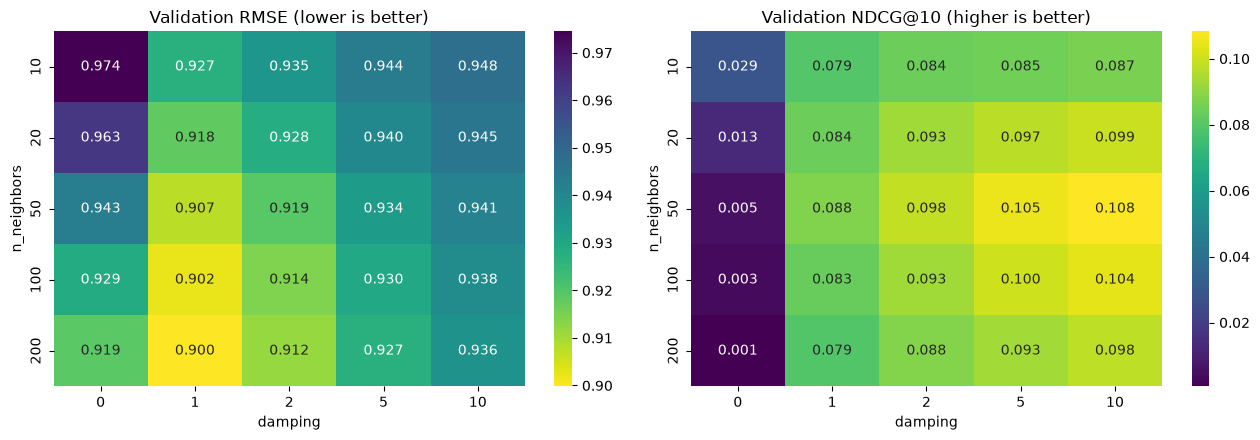

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
panels = [
    ("rmse", "viridis_r", "Validation RMSE (lower is better)"),
    ("ndcg@10", "viridis", "Validation NDCG@10 (higher is better)"),
]
for ax, (metric, colors, title) in zip(axes, panels):
    table = grid.pivot(index="n_neighbors", columns="damping", values=metric)
    sns.heatmap(table, annot=True, fmt=".3f", cmap=colors, ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [6]:
# Two different goals can prefer different settings, so we pick one set for each
best_rmse = grid.loc[grid["rmse"].idxmin()]
best_ndcg = grid.loc[grid["ndcg@10"].idxmax()]
print(f"Best for rating prediction: n_neighbors={best_rmse['n_neighbors']:.0f}, "
      f"damping={best_rmse['damping']:g} (validation RMSE {best_rmse['rmse']:.4f})")
print(f"Best for the top-10 list:   n_neighbors={best_ndcg['n_neighbors']:.0f}, "
      f"damping={best_ndcg['damping']:g} (validation NDCG@10 {best_ndcg['ndcg@10']:.4f})")

Best for rating prediction: n_neighbors=200, damping=1 (validation RMSE 0.8998)
Best for the top-10 list:   n_neighbors=50, damping=10 (validation NDCG@10 0.1083)


## 2. The final check on the test set

Now we refit on the **whole** training set with the two chosen settings and score them on the test set, once. The baseline rows are the ones from notebook 02 (`docs/results.csv`).

In [7]:
chosen = dict.fromkeys(
    [
        (int(best_rmse["n_neighbors"]), float(best_rmse["damping"])),
        (int(best_ndcg["n_neighbors"]), float(best_ndcg["damping"])),
    ]
)  # a dict keeps the order and drops a duplicate if both goals chose the same settings

final = pd.DataFrame(
    [{"split": "user_time"} | evaluate(UserKNN(n, d), train, test) for n, d in chosen]
)

baselines = pd.read_csv("../docs/results.csv")
baselines = baselines[(baselines["split"] == "user_time") & ~baselines["model"].str.startswith("User KNN")]
pd.concat([baselines, final], ignore_index=True).round(4)

,split,model,rmse,mae,precision@10,recall@10,ndcg@10
0,user_time,Global mean,1.0688,0.8360,NaN,NaN,NaN
1,user_time,Movie mean,1.0227,0.7867,0.0000,0.0000,0.0000
2,user_time,Movie mean (damping=10),1.0051,0.7777,0.0428,0.0330,0.0551
3,user_time,Popularity,NaN,NaN,0.0563,0.0507,0.0741
4,user_time,"User KNN (k=200, damping=1.0)",0.9086,0.6950,0.0631,0.0596,0.0847
5,user_time,"User KNN (k=50, damping=10.0)",0.9526,0.7373,0.0765,0.0744,0.1000


## 3. Where does KNN struggle?

KNN learns from other users' ratings of the *same movie*, so it should be weaker on movies that almost nobody rated. We group the test ratings by how many training ratings their movie has, and compare the rating error (RMSE) of the best KNN with the damped movie-mean baseline.

In [8]:
knn = UserKNN(int(best_rmse["n_neighbors"]), float(best_rmse["damping"])).fit(train)
baseline = MovieMean(damping=10).fit(train)

train_counts = train["movieId"].value_counts()
test_view = test.assign(
    train_ratings=test["movieId"].map(train_counts).fillna(0),  # 0 = movie never seen in train
    knn_pred=knn.predict(test),
    baseline_pred=baseline.predict(test),
)
test_view["movie group"] = pd.cut(
    test_view["train_ratings"],
    bins=[-1, 0, 3, 10, 50, np.inf],
    labels=["0 (unseen)", "1-3", "4-10", "11-50", "more than 50"],
)


def group_rmse(group):
    return pd.Series(
        {
            "test ratings": len(group),
            "KNN RMSE": rmse(group["rating"], group["knn_pred"]),
            "Movie mean RMSE": rmse(group["rating"], group["baseline_pred"]),
        }
    )


by_group = test_view.groupby("movie group", observed=True).apply(group_rmse)
by_group["KNN advantage"] = by_group["Movie mean RMSE"] - by_group["KNN RMSE"]
by_group.round(3)

,test ratings,KNN RMSE,Movie mean RMSE,KNN advantage
movie group,,,,
0 (unseen),1682.0,1.002,1.188,0.187
1-3,2634.0,0.928,1.069,0.141
4-10,3327.0,0.929,1.025,0.096
11-50,7767.0,0.877,0.957,0.080
more than 50,4530.0,0.898,0.957,0.058


## Findings

- **Two goals, two settings.** On the validation set, `n_neighbors=200, damping=1` gave the best rating error (RMSE 0.900) and `n_neighbors=50, damping=10` the best top-10 list (NDCG@10 0.108). Both winners sit on the edge of the grid (the most neighbours, the most damping), so larger values might still help. That is not tested yet.
- **Damping decides whether the ranking works.** With `damping=0` the RMSE is acceptable, but the top-10 list collapses (validation NDCG@10 below 0.03). A movie that only one or two similar users rated, and loved, jumps to the top. It is the same failure as the plain movie mean in notebook 02, and damping fixes it the same way.
- **KNN beats the baselines on the test set.** For rating prediction, `k=200, damping=1` reaches RMSE 0.909 against 1.005 for the best baseline (about 10% lower). For the top-10 list, `k=50, damping=10` reaches NDCG@10 0.100 and Precision@10 0.077 against 0.074 and 0.056 for popularity (about 35% higher). The RMSE-optimal setting still beats popularity on ranking (NDCG@10 0.085), but by less.
- **Rarely rated movies stay hard.** 21.6% of the test ratings belong to movies with 3 or fewer training ratings (4,316 of 19,940). KNN's error is higher there (RMSE 0.93 to 1.00) than for movies with 11 to 50 ratings (0.88). For a movie never seen in training, KNN can only fall back on the user's own average. Its lead over the movie-mean baseline is largest in these groups only because the baseline has just the global average to fall back on.
- **What this means for the hybrid.** Collaborative filtering has no information about unseen and rarely rated movies, and that is exactly where the content-based model (genres and plot text) can help. The hybrid should be judged mainly on these groups.

## Saving the results

The final rows are added to the shared table `docs/results.csv`. Re-running this notebook replaces the old KNN rows instead of duplicating them.

In [9]:
results = pd.read_csv("../docs/results.csv")
results = results[~results["model"].str.startswith("User KNN")]
pd.concat([results, final], ignore_index=True).to_csv("../docs/results.csv", index=False)
print("Saved to docs/results.csv")

Saved to docs/results.csv
